# Ucitavanje

In [7]:
import numpy as np
import os

snapshots = [99, 50, 33, 25]

fields = [
    "SubhaloMassType",
    "SubhaloSFR",
    "SubhaloGasMetallicitySfrWeighted"
]

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    print("\n" + "=" * 60)
    print(f"SNAPSHOT {snap}")
    print("=" * 60)

    if not os.path.exists(filename):
        print("Fajl ne postoji!")
        continue

    data = np.load(filename)

    # Broj ID-jeva
    ids = data["SubhaloID"]

    print(f"\nBroj subhaloa (ID): {len(ids)}")

    # Provera svakog polja
    lengths = []

    for field in fields:

        array = data[field]

        lengths.append(len(array))

        print(f"{field}:")
        print(f"    Oblik: {array.shape}")
        print(f"    Broj redova: {len(array)}")

    # Provera jednakog broja redova
    if len(set(lengths + [len(ids)])) == 1:

        print("\nSVI NIZOVI IMAJU ISTI BROJ REDOVA.")

    else:

        print("\nGRESKA: BROJ REDOVA SE NE POKLAPA")

    # Provera ID-jeva
    expected_ids = np.arange(len(ids))

    if np.array_equal(ids, expected_ids):

        print("ID-jevi odgovaraju indeksima u katalogu.")

    else:

        print("GRESKA: ID-jevi nisu pravilno poređani")

    # Provera da li postoje duplikati
    if len(np.unique(ids)) == len(ids):

        print("Nema dupliranih ID-jeva.")

    else:

        print("GRESKA: Postoje duplirani ID-jevi.")

    # Provera nedostajućih vrednosti
    for field in fields:

        array = data[field]

        print(
            f"{field} | NaN vrednosti:",
            np.isnan(array).sum()
        )


SNAPSHOT 99

Broj subhaloa (ID): 4371211
SubhaloMassType:
    Oblik: (4371211, 6)
    Broj redova: 4371211
SubhaloSFR:
    Oblik: (4371211,)
    Broj redova: 4371211
SubhaloGasMetallicitySfrWeighted:
    Oblik: (4371211,)
    Broj redova: 4371211

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 50

Broj subhaloa (ID): 5127294
SubhaloMassType:
    Oblik: (5127294, 6)
    Broj redova: 5127294
SubhaloSFR:
    Oblik: (5127294,)
    Broj redova: 5127294
SubhaloGasMetallicitySfrWeighted:
    Oblik: (5127294,)
    Broj redova: 5127294

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 33

Broj subhaloa (ID): 5621338
SubhaloMassType:
    Obl

In [8]:
import numpy as np

snapshots = [99, 50, 33, 25]

all_data = {}

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    loaded = np.load(filename)

    all_data[snap] = {
        key: loaded[key]
        for key in loaded.files
    }

    loaded.close()

    print(f'Snapshot {snap}: učitan')

Snapshot 99: učitan
Snapshot 50: učitan
Snapshot 33: učitan
Snapshot 25: učitan


# Opseg masa 9 < log M* < 11,2 i pozitivni SFR za SFMS

In [11]:
snapshots = [99, 50, 33, 25]

filtered_data = {}

for snap in snapshots:

    print("\n" + "=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)

    data = all_data[snap]

    
    N_before = len(data["SubhaloID"])

    
    stellar_mass = data["SubhaloMassType"][:, 4]

    
    stellar_mass_msun = stellar_mass * 1e10 / 0.6774

    
    logM = np.full(len(stellar_mass), np.nan)
    positive_mass = stellar_mass_msun > 0
    logM[positive_mass] = np.log10(stellar_mass_msun[positive_mass])

    
    sfr = data["SubhaloSFR"]
    mask=(
        (logM > 9) &
        (logM < 11.2) &
        (sfr > 0)
    )
    
    N_after = np.sum(mask)

    
    N_removed = N_before - N_after

    
    filtered_data[snap] = {
        field: data[field][mask]
        for field in [
            "SubhaloID",
            "SubhaloMassType",
            "SubhaloSFR",
            "SubhaloGasMetallicitySfrWeighted"
        ]
    }

    print("Broj objekata pre filtriranja:", N_before)
    print("Broj objekata nakon filtriranja:", N_after)
    print("Broj izbačenih objekata:", N_removed)

    print(
        "Procenat izbačenih objekata:",
        round(100 * N_removed / N_before, 2), "%"
    )


SNAPSHOT 99
Broj objekata pre filtriranja: 4371211
Broj objekata nakon filtriranja: 17163
Broj izbačenih objekata: 4354048
Procenat izbačenih objekata: 99.61 %

SNAPSHOT 50
Broj objekata pre filtriranja: 5127294
Broj objekata nakon filtriranja: 17412
Broj izbačenih objekata: 5109882
Procenat izbačenih objekata: 99.66 %

SNAPSHOT 33
Broj objekata pre filtriranja: 5621338
Broj objekata nakon filtriranja: 12254
Broj izbačenih objekata: 5609084
Procenat izbačenih objekata: 99.78 %

SNAPSHOT 25
Broj objekata pre filtriranja: 5828784
Broj objekata nakon filtriranja: 6738
Broj izbačenih objekata: 5822046
Procenat izbačenih objekata: 99.88 %


# SFMS

In [19]:
from sklearn.linear_model import HuberRegressor
import pandas as pd

TNG_populations = {}
MW_statistics = {}

snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]

for snap, z in snapshot_redshifts.items():

    data = filtered_data[snap]

    # Izvlacenje zvezdane mase i SFR-a
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / 0.6774

    # Logaritamske vrednosti
    logM = np.log10(mass_msun)
    logSFR = np.log10(sfr)

    # SFMS fit pomocu Huber regresije
    X = logM.reshape(-1, 1)
    y = logSFR

    huber = HuberRegressor()
    huber.fit(X, y)

    # Odstupanje od SFMS relacije
    logSFR_fit = huber.predict(X)
    delta_logSFR = logSFR - logSFR_fit

    # Podela na upper i lower populaciju
    upper_mask = delta_logSFR > -1
    lower_mask = delta_logSFR <= -1

    upper = pd.DataFrame({
        "id": data["SubhaloID"][upper_mask],
        "logM": logM[upper_mask],
        "logSFR": logSFR[upper_mask],
        "delta_logSFR": delta_logSFR[upper_mask]
    })

    lower = pd.DataFrame({
        "id": data["SubhaloID"][lower_mask],
        "logM": logM[lower_mask],
        "logSFR": logSFR[lower_mask],
        "delta_logSFR": delta_logSFR[lower_mask]
    })
    
    # Cuvanje rezultata
    TNG_populations[z] = {
        "all": pd.DataFrame({
            "id": data["SubhaloID"],
            "logM": logM,
            "logSFR": logSFR,
            "delta_logSFR": delta_logSFR
        }),
        "upper": upper,
        "lower": lower,
        "huber": huber
    }
    

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Ukupan broj galaksija: {len(data['SubhaloID'])}")
    print(f"Upper populacija: {len(upper)}")
    print(f"Lower populacija: {len(lower)}")
    print(f"SFMS nagib: {huber.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber.intercept_:.4f}")

SNAPSHOT 99 | z = 0
Ukupan broj galaksija: 17163
Upper populacija: 16050
Lower populacija: 1113
SFMS nagib: 0.6496
SFMS odsečak: -6.6459
SNAPSHOT 50 | z = 1
Ukupan broj galaksija: 17412
Upper populacija: 16661
Lower populacija: 751
SFMS nagib: 0.7935
SFMS odsečak: -7.4684
SNAPSHOT 33 | z = 2
Ukupan broj galaksija: 12254
Upper populacija: 11961
Lower populacija: 293
SFMS nagib: 0.7879
SFMS odsečak: -6.9918
SNAPSHOT 25 | z = 3
Ukupan broj galaksija: 6738
Upper populacija: 6699
Lower populacija: 39
SFMS nagib: 0.9051
SFMS odsečak: -7.8110


# SFMS refit

In [20]:
TNG_refit_results = {}

for z in snapshot_redshifts.values():

    all_data_z = TNG_populations[z]["all"]
    upper = TNG_populations[z]["upper"]

    
    X_upper = upper["logM"].values.reshape(-1, 1)
    y_upper = upper["logSFR"].values

    
    huber_refit = HuberRegressor()
    huber_refit.fit(X_upper, y_upper)

    X_all = all_data_z["logM"].values.reshape(-1, 1)

    logSFR_fit_refit = huber_refit.predict(X_all)

    delta_refit = (
        all_data_z["logSFR"].values - logSFR_fit_refit
    )

    upper_refit_mask = delta_refit > -1
    lower_refit_mask = delta_refit <= -1

    all_refit = all_data_z.copy()
    all_refit["logSFR_fit_refit"] = logSFR_fit_refit
    all_refit["delta_refit"] = delta_refit

    upper_refit = all_refit[upper_refit_mask].copy()
    lower_refit = all_refit[lower_refit_mask].copy()

    TNG_refit_results[z] = {
        "all": all_refit,
        "upper": upper_refit,
        "lower": lower_refit,
        "huber_refit": huber_refit
    }

    huber_initial = TNG_populations[z]["huber"]

    print("=" * 50)
    print(f"SNAPSHOT | z = {z}")
    print("=" * 50)

    print(f"Broj galaksija u početnoj upper populaciji: {len(upper)}")
    print(f"Nova upper populacija: {len(upper_refit)}")
    print(f"Nova lower populacija: {len(lower_refit)}")

    print("\nInicijalna SFMS:")
    print(f"Nagib: {huber_initial.coef_[0]:.4f}")
    print(f"Odsečak: {huber_initial.intercept_:.4f}")

    print("\nRefitovana SFMS:")
    print(f"Nagib: {huber_refit.coef_[0]:.4f}")
    print(f"Odsečak: {huber_refit.intercept_:.4f}")

SNAPSHOT | z = 0
Broj galaksija u početnoj upper populaciji: 16050
Nova upper populacija: 15952
Nova lower populacija: 1211

Inicijalna SFMS:
Nagib: 0.6496
Odsečak: -6.6459

Refitovana SFMS:
Nagib: 0.7386
Odsečak: -7.4654
SNAPSHOT | z = 1
Broj galaksija u početnoj upper populaciji: 16661
Nova upper populacija: 16621
Nova lower populacija: 791

Inicijalna SFMS:
Nagib: 0.7935
Odsečak: -7.4684

Refitovana SFMS:
Nagib: 0.8407
Odsečak: -7.9066
SNAPSHOT | z = 2
Broj galaksija u početnoj upper populaciji: 11961
Nova upper populacija: 11953
Nova lower populacija: 301

Inicijalna SFMS:
Nagib: 0.7879
Odsečak: -6.9918

Refitovana SFMS:
Nagib: 0.8128
Odsečak: -7.2233
SNAPSHOT | z = 3
Broj galaksija u početnoj upper populaciji: 6699
Nova upper populacija: 6699
Nova lower populacija: 39

Inicijalna SFMS:
Nagib: 0.9051
Odsečak: -7.8110

Refitovana SFMS:
Nagib: 0.9131
Odsečak: -7.8858


# COSMOS

In [27]:
import pandas as pd
import numpy as np
from astropy.table import Table

COSMOS_FILE = "asu.fit"


# Učitavanje FITS fajla
cos = Table.read(
    COSMOS_FILE,
    format="fits"
).to_pandas()

# Ovde sam stavila filter za logsfr jer inace ide do -100
cos = cos[
    (cos["SFR"] > -4)
].copy()

# Definisanje logaritamskih veličina
cos["logM"] = cos["MassMed"]
cos["logSFR"] = cos["SFR"]

print(f"Broj COSMOS objekata nakon filtriranja: {len(cos)}")


# Podela podataka po intervalima crvenog pomaka

def get_cosmos_bin(z):

    if z == 0:
        return cos[
            (cos["zphot"] >= 0) &
            (cos["zphot"] < 0.5)
        ].copy()

    elif z == 1:
        return cos[
            (cos["zphot"] >= 0.5) &
            (cos["zphot"] < 1)
        ].copy()

    elif z == 2:
        return cos[
            (cos["zphot"] >= 1) &
            (cos["zphot"] < 2)
        ].copy()

    elif z == 3:
        return cos[
            (cos["zphot"] >= 2) &
            (cos["zphot"] < 4)
        ].copy()


# Izdvajanje populacija po crvenom pomaku
COSMOS_data = {}

for z in range(4):

    COSMOS_data[z] = get_cosmos_bin(z)

    print(f"z = {z}: {len(COSMOS_data[z])} galaksija")

Broj COSMOS objekata nakon filtriranja: 581195
z = 0: 88016 galaksija
z = 1: 125257 galaksija
z = 2: 166470 galaksija
z = 3: 123336 galaksija


# Figure 1


z = 0
Ukupno TNG galaksija: 71575
Active: 63644
ReducedSFR: 7931
MW_masslike: 1182
Active MW_masslike: 849
Udeo aktivnih galaksija u MW_masslike: 71.83%

z = 1
Ukupno TNG galaksija: 147241
Active: 127774
ReducedSFR: 19467
MW_masslike: 1822
Active MW_masslike: 1633
Udeo aktivnih galaksija u MW_masslike: 89.63%

z = 2
Ukupno TNG galaksija: 274398
Active: 199344
ReducedSFR: 75054
MW_masslike: 1486
Active MW_masslike: 1461
Udeo aktivnih galaksija u MW_masslike: 98.32%

z = 3
Ukupno TNG galaksija: 425208
Active: 352341
ReducedSFR: 72867
MW_masslike: 1113
Active MW_masslike: 1112
Udeo aktivnih galaksija u MW_masslike: 99.91%


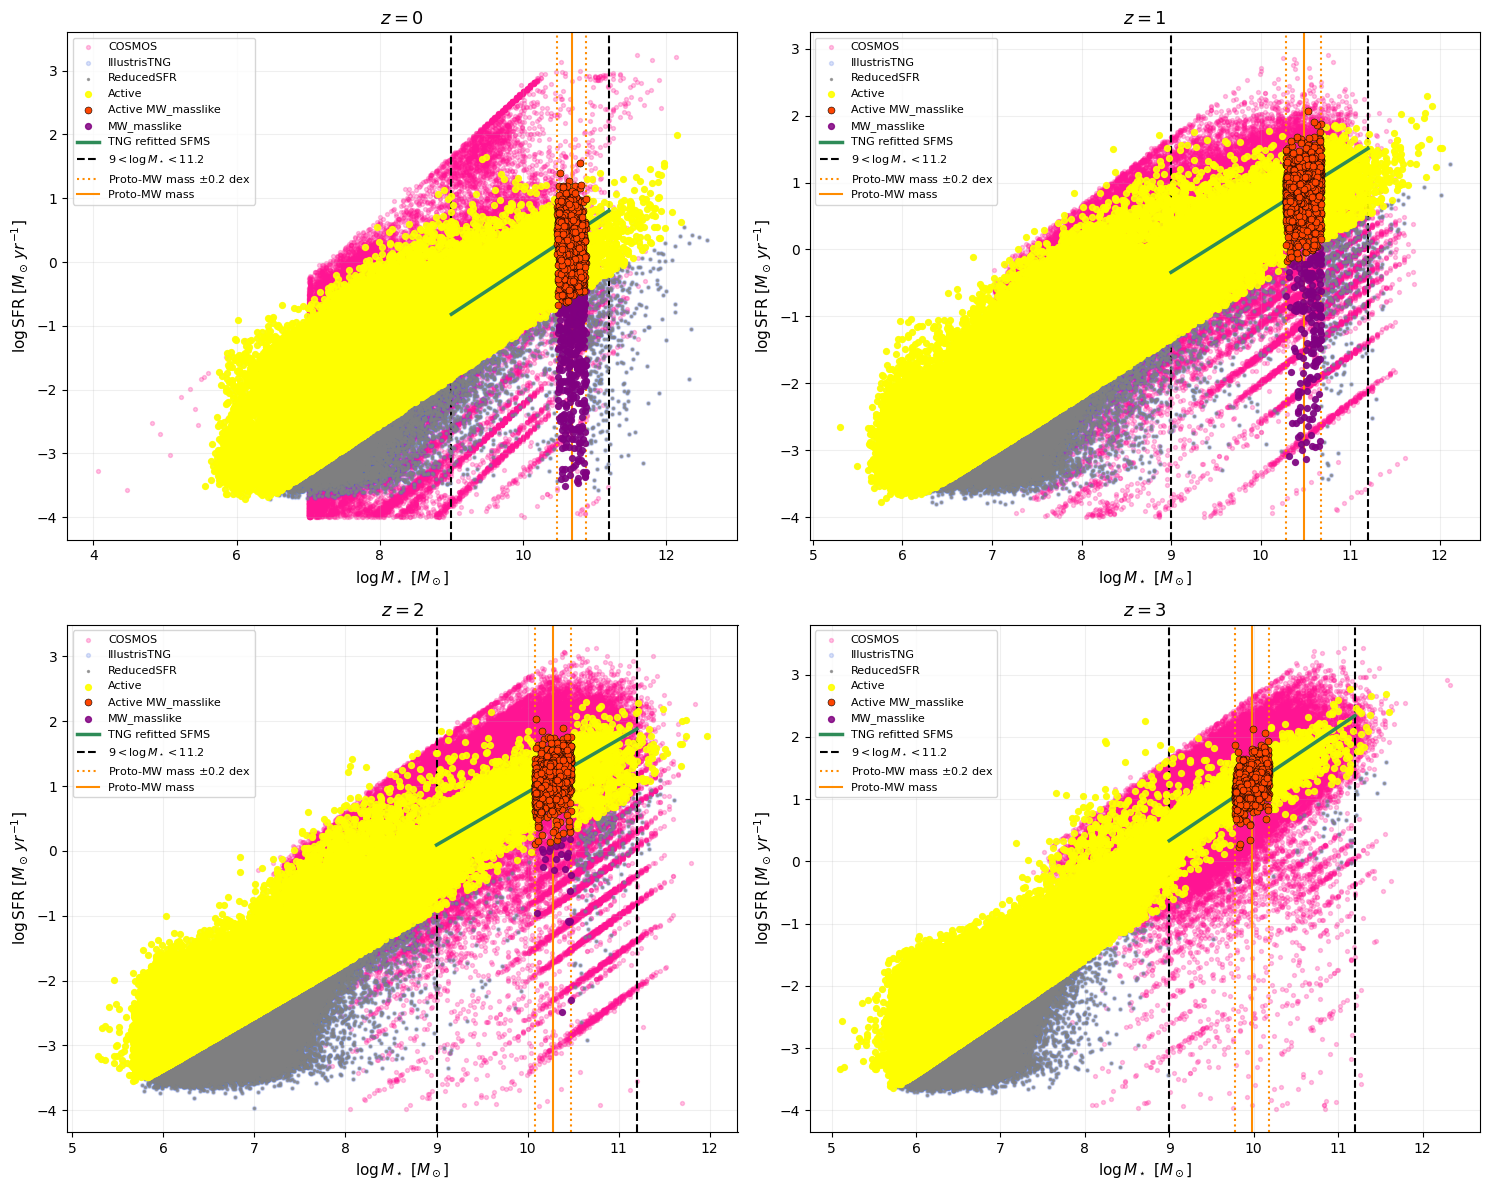

In [36]:

import numpy as np
import matplotlib.pyplot as plt

protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]

# Boje
COSMOS_COLOR = "deeppink"
TNG_COLOR = "royalblue"
SFMS_COLOR = "seagreen"
MWmass_COLOR = "purple"

# Figura sa četiri panela
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for i, (snap, z) in enumerate(snapshot_redshifts.items()):

    ax = axes[i]

    # ==========================================
    # 1. COSMOS PODACI
    # ==========================================

    cos_sub = COSMOS_data[z]

    ax.scatter(
        cos_sub["logM"],
        cos_sub["logSFR"],
        s=8,
        alpha=0.25,
        color=COSMOS_COLOR,
        label="COSMOS",
        rasterized=True
    )

    # ==========================================
    # 2. SVI TNG PODACI (POZITIVNA MASA I SFR)
    # ==========================================

    data = all_data[snap]

    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Selekcija pozitivne mase i SFR-a
    mask = (
        (stellar_mass > 0) &
        (sfr > 0)
    )

    # Konverzija mase u Msun
    mass_msun = stellar_mass[mask] * 1e10 / 0.6774

    # Logaritamske vrednosti
    logM_TNG = np.log10(mass_msun)
    logSFR_TNG = np.log10(sfr[mask])

    # Sve TNG galaksije
    ax.scatter(
        logM_TNG,
        logSFR_TNG,
        s=8,
        alpha=0.2,
        color=TNG_COLOR,
        label="IllustrisTNG",
        rasterized=True,
        zorder=1
    )

    # ==========================================
    # 3. KLASIFIKACIJA SVIH TNG GALAKSIJA
    # ==========================================

    # Refitted SFMS
    huber_refit = TNG_refit_results[z]["huber_refit"]

    # Predikcija za sve TNG galaksije
    logSFR_fit_all = huber_refit.predict(
        logM_TNG.reshape(-1, 1)
    )

    # Odstupanje od refitovane SFMS
    delta_logSFR_all = logSFR_TNG - logSFR_fit_all

    # Active: delta_logSFR > -1
    active_mask = delta_logSFR_all > -1

    # ReducedSFR: delta_logSFR <= -1
    reduced_mask = delta_logSFR_all <= -1

    # ReducedSFR galaksije
    ax.scatter(
        logM_TNG[reduced_mask],
        logSFR_TNG[reduced_mask],
        s=2,
        alpha=0.7,
        color="gray",
        label="ReducedSFR",
        rasterized=True,
        zorder=3
    )

    # Active galaksije
    ax.scatter(
        logM_TNG[active_mask],
        logSFR_TNG[active_mask],
        s=18,
        alpha=0.9,
        color="yellow",
        label="Active",
        rasterized=True,
        zorder=5
    )

    # ==========================================
    # 4. ACTIVE MW_masslike GALAKSIJE
    # ==========================================

    MW_mass = protoMWmass[z]

    MW_active_mask = (
        (logM_TNG >= MW_mass - 0.2) &
        (logM_TNG <= MW_mass + 0.2) &
        active_mask
    )

    ax.scatter(
        logM_TNG[MW_active_mask],
        logSFR_TNG[MW_active_mask],
        s=25,
        alpha=1,
        color="orangered",
        edgecolors="black",
        linewidths=0.4,
        label="Active MW_masslike",
        rasterized=True,
        zorder=7
    )

    # ==========================================
    # 5. MW MASS-LIKE POPULACIJA
    # ==========================================

    MW_mask = (
        (logM_TNG >= MW_mass - 0.2) &
        (logM_TNG <= MW_mass + 0.2)
    )

    ax.scatter(
        logM_TNG[MW_mask],
        logSFR_TNG[MW_mask],
        s=18,
        alpha=0.85,
        color=MWmass_COLOR,
        label="MW_masslike",
        rasterized=True,
        zorder=4
    )

    # ==========================================
    # 6. REFITOVANA SFMS RELACIJA
    # ==========================================

    x_fit = np.linspace(9, 11.2, 200)

    y_fit = huber_refit.predict(
        x_fit.reshape(-1, 1)
    )

    ax.plot(
        x_fit,
        y_fit,
        color=SFMS_COLOR,
        linewidth=2.5,
        label="TNG refitted SFMS",
        zorder=6
    )

    # ==========================================
    # 7. MASENI INTERVAL 9–11.2
    # ==========================================

    ax.axvline(
        9,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=r"$9 < \log M_\star < 11.2$"
    )

    ax.axvline(
        11.2,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    # ==========================================
    # 8. PROTO-MW MASA ±0.2 dex
    # ==========================================

    ax.axvline(
        MW_mass - 0.2,
        color="darkorange",
        linestyle=":",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm 0.2$ dex"
    )

    ax.axvline(
        MW_mass + 0.2,
        color="darkorange",
        linestyle=":",
        linewidth=1.5
    )

    ax.axvline(
        MW_mass,
        color="darkorange",
        linestyle="-",
        linewidth=1.5,
        label="Proto-MW mass"
    )

    # ==========================================
    # 9. BROJ GALAKSIJA
    # ==========================================

    print(f"\nz = {z}")
    print(f"Ukupno TNG galaksija: {len(logM_TNG)}")
    print(f"Active: {np.sum(active_mask)}")
    print(f"ReducedSFR: {np.sum(reduced_mask)}")
    print(f"MW_masslike: {np.sum(MW_mask)}")
    print(f"Active MW_masslike: {np.sum(MW_active_mask)}")

    MW_active_fraction = np.sum(MW_active_mask) / np.sum(MW_mask)
    print(f"Udeo aktivnih galaksija u MW_masslike: {MW_active_fraction:.2%}")


    # ==========================================
    # 10. PODESAVANJE GRAFIKA
    # ==========================================

    ax.set_xlabel(
        r"$\log M_\star\ [M_\odot]$",
        fontsize=11
    )

    ax.set_ylabel(
        r"$\log \mathrm{SFR}\ [M_\odot\,yr^{-1}]$",
        fontsize=11
    )

    ax.set_title(
        f"$z = {z}$",
        fontsize=13
    )

    ax.grid(alpha=0.2)

    ax.legend(
        fontsize=8,
        loc="best"
    )

plt.tight_layout()
plt.show()

# Fizički parametri

In [38]:
results = []

for snap, z in snapshot_redshifts.items():

    data = all_data[snap]

    # Pozitivna masa i SFR
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    mask = (stellar_mass > 0) & (sfr > 0)

    mass_msun = stellar_mass[mask] * 1e10 / 0.6774
    logM_TNG = np.log10(mass_msun)
    logSFR_TNG = np.log10(sfr[mask])

    # Metalicitet
    Z_TNG = data["SubhaloGasMetallicitySfrWeighted"][mask]

    # Refitted SFMS
    huber_refit = TNG_refit_results[z]["huber_refit"]

    logSFR_fit = huber_refit.predict(
        logM_TNG.reshape(-1, 1)
    )

    delta_logSFR = logSFR_TNG - logSFR_fit

    # Active MW_masslike selekcija
    MW_mass = protoMWmass[z]

    MW_active_mask = (
        (logM_TNG >= MW_mass - 0.2) &
        (logM_TNG <= MW_mass + 0.2) &
        (delta_logSFR > -1)
    )

    # Izdvajanje populacije
    active_MW_logM = logM_TNG[MW_active_mask]
    active_MW_logSFR = logSFR_TNG[MW_active_mask]
    active_MW_Z = Z_TNG[MW_active_mask]

    # Funkcija za statistiku
    def get_statistics(values):
        values = values[np.isfinite(values)]

        if len(values) == 0:
            return np.nan, np.nan, np.nan

        p16, median, p84 = np.percentile(
            values, [16, 50, 84]
        )

        return median, p16, p84

    # Statistika za svaku veličinu
    mass_stats = get_statistics(active_MW_logM)
    sfr_stats = get_statistics(active_MW_logSFR)
    Z_stats = get_statistics(active_MW_Z)

    results.append({
        "z": z,
        "N": len(active_MW_logM),

        "logM_median": mass_stats[0],
        "logM_p16": mass_stats[1],
        "logM_p84": mass_stats[2],

        "logSFR_median": sfr_stats[0],
        "logSFR_p16": sfr_stats[1],
        "logSFR_p84": sfr_stats[2],

        "Z_median": Z_stats[0],
        "Z_p16": Z_stats[1],
        "Z_p84": Z_stats[2]
    })

# Kreiranje i prikaz tabele
MW_active_statistics = pd.DataFrame(results)

display(
    MW_active_statistics.round(4).set_index("z")
)

,N,logM_median,logM_p16,logM_p84,logSFR_median,logSFR_p16,logSFR_p84,Z_median,Z_p16,Z_p84
z,,,,,,,,,,
0,849,10.6249,10.5228,10.7736,0.3462,-0.1767,0.7151,0.0178,0.0112,0.0299
1,1633,10.4507,10.3293,10.5973,0.9289,0.6259,1.1706,0.0241,0.0172,0.0328
2,1461,10.2538,10.1308,10.4013,1.1130,0.8815,1.3370,0.0226,0.0177,0.0296
3,1112,9.9625,9.8296,10.1036,1.2287,1.0597,1.4121,0.0157,0.0122,0.0207


# Procenat MW-like aktivnih galaksija u top 10% Np za TNG galaksije (opseg masa 9 < log M* < 11,2 i pozitivni SFR za SFMS)

In [57]:
alpha_values = [0, 1]

Np_results = []

Np_common_IDs = {}

for snap, z in snapshot_redshifts.items():

    data = all_data[snap]

    subhalo_ids = data["SubhaloID"]
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]
    Z = data["SubhaloGasMetallicitySfrWeighted"]

    mass_msun = stellar_mass * 1e10 / 0.6774

    valid_positive = (
        (stellar_mass > 0) &
        (sfr > 0) &
        np.isfinite(mass_msun) &
        np.isfinite(sfr)
    )

    logM = np.full(len(stellar_mass), np.nan)
    logSFR = np.full(len(sfr), np.nan)

    logM[valid_positive] = np.log10(
        mass_msun[valid_positive]
    )

    logSFR[valid_positive] = np.log10(
        sfr[valid_positive]
    )


    huber_refit = TNG_refit_results[z]["huber_refit"]

    logSFR_fit = np.full(len(sfr), np.nan)

    logSFR_fit[valid_positive] = huber_refit.predict(
        logM[valid_positive].reshape(-1, 1)
    )

    delta_logSFR = logSFR - logSFR_fit


    MW_mass = protoMWmass[z]

    MW_active_mask = (
        valid_positive &
        (logM >= MW_mass - 0.2) &
        (logM <= MW_mass + 0.2) &
        (delta_logSFR > -1)
    )


    TNG_mask = (
        valid_positive &
        (logM > 9) &
        (logM < 11.2)
    )

    for alpha in alpha_values:
    

        final_TNG_mask = TNG_mask
        final_MW_mask = MW_active_mask

        

        TNG_ids = subhalo_ids[final_TNG_mask]
        MW_ids = subhalo_ids[final_MW_mask]


        logNp_TNG = (
            2 * logM[final_TNG_mask]
            - logSFR[final_TNG_mask]
        )

        logNp_MW = (
            2 * logM[final_MW_mask]
            - logSFR[final_MW_mask]
        )

        if alpha == 1:

            logNp_TNG += np.log10(
                Z[final_TNG_mask]
            )

            logNp_MW += np.log10(
                Z[final_MW_mask]
            )

        # Odredjujem 90percentile
        Np_threshold = np.percentile(
            logNp_TNG, 90
        )

        top10_mask = logNp_TNG >= Np_threshold

        top10_ids = TNG_ids[top10_mask]


        
        # Poredjenje IDeva
        common_ids = np.intersect1d(
            MW_ids,
            top10_ids
        )

        N_overlap = len(common_ids)

        

        if len(MW_ids) > 0:
            overlap_percentage = N_overlap * 100 / len(MW_ids)
        else:
            overlap_percentage = np.nan

        Np_results.append({
    "z": z,
    "alpha": alpha,
    "N_TNG": len(TNG_ids),
    "N_Active_MW": len(MW_ids),
    "N_TNG_top10": len(top10_ids),
    "N_common": N_overlap,
    "Overlap_percent": overlap_percentage
})

        Np_common_IDs[(z, alpha)] = common_ids.tolist()


        print("=" * 60)
        print(f"REDSHIFT z = {z} | ALPHA = {alpha}")
        print("=" * 60)

        print(f"Ukupno TNG galaksija: {len(TNG_ids)}")
        print(f"Active MW-like galaksija: {len(MW_ids)}")
        print(f"TNG top 10% galaksija: {len(top10_ids)}")
        print(f"Zajedničkih galaksija: {N_overlap}")
        print(f"Procenat aktivnih MW-like galaksija u TNG top 10%: " f"{overlap_percentage:.2f}%")

REDSHIFT z = 0 | ALPHA = 0
Ukupno TNG galaksija: 17163
Active MW-like galaksija: 849
TNG top 10% galaksija: 1717
Zajedničkih galaksija: 425
Procenat aktivnih MW-like galaksija u TNG top 10%: 50.06%
REDSHIFT z = 0 | ALPHA = 1
Ukupno TNG galaksija: 17163
Active MW-like galaksija: 849
TNG top 10% galaksija: 1717
Zajedničkih galaksija: 335
Procenat aktivnih MW-like galaksija u TNG top 10%: 39.46%
REDSHIFT z = 1 | ALPHA = 0
Ukupno TNG galaksija: 17412
Active MW-like galaksija: 1633
TNG top 10% galaksija: 1742
Zajedničkih galaksija: 327
Procenat aktivnih MW-like galaksija u TNG top 10%: 20.02%
REDSHIFT z = 1 | ALPHA = 1
Ukupno TNG galaksija: 17412
Active MW-like galaksija: 1633
TNG top 10% galaksija: 1742
Zajedničkih galaksija: 316
Procenat aktivnih MW-like galaksija u TNG top 10%: 19.35%
REDSHIFT z = 2 | ALPHA = 0
Ukupno TNG galaksija: 12254
Active MW-like galaksija: 1461
TNG top 10% galaksija: 1226
Zajedničkih galaksija: 245
Procenat aktivnih MW-like galaksija u TNG top 10%: 16.77%
REDSHIF